In [2]:
!pip install -q transformers datasets accelerate evaluate

from google.colab import drive
drive.mount('/content/drive')

import os, time
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import seaborn as sns
from datasets import Dataset, DatasetDict
from sklearn.metrics import f1_score, accuracy_score, classification_report, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight
from transformers import (
    AutoTokenizer, AutoModelForSequenceClassification,
    TrainingArguments, Trainer, DataCollatorWithPadding,
    EarlyStoppingCallback,
)

print(f"CUDA available: {torch.cuda.is_available()}")
print(f"Device:         {torch.cuda.get_device_name(0)}")
print(f"GPU memory:     {torch.cuda.get_device_properties(0).total_memory / 1024**3:.1f} GB")

Mounted at /content/drive
CUDA available: True
Device:         Tesla T4
GPU memory:     14.6 GB


In [2]:
DATA_DIR   = "/content/drive/MyDrive/thesis_stage2"
MODEL_NAME = "roberta-base"

OUTPUT_DIR = f"{DATA_DIR}/roberta_therapistqa_seed42_v3"
FINAL_DIR  = f"{DATA_DIR}/roberta_therapistqa_final_v3"

df_train = pd.read_csv(f"{DATA_DIR}/therapistqa_train.csv")
df_val   = pd.read_csv(f"{DATA_DIR}/therapistqa_val.csv")
df_test  = pd.read_csv(f"{DATA_DIR}/therapistqa_test.csv")

classes  = sorted(df_train["dominant_distortion"].unique())
label2id = {label: idx for idx, label in enumerate(classes)}
id2label = {idx: label for label, idx in label2id.items()}

print(f"Train: {len(df_train)}, Val: {len(df_val)}, Test: {len(df_test)}")
print(f"Classes ({len(classes)}):")
for idx, name in id2label.items():
    print(f"  {idx}: {name}")

Train: 1768, Val: 379, Test: 379
Classes (11):
  0: All-or-nothing thinking
  1: Emotional Reasoning
  2: Fortune-telling
  3: Labeling
  4: Magnification
  5: Mental filter
  6: Mind Reading
  7: No Distortion
  8: Overgeneralization
  9: Personalization
  10: Should statements


In [3]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def make_dataset(df):
    return Dataset.from_pandas(
        df[["patient_question", "dominant_distortion"]]
            .rename(columns={"patient_question": "text"})
            .assign(label=lambda d: d["dominant_distortion"].map(label2id))
            [["text", "label"]],
        preserve_index=False,
    )

raw_datasets = DatasetDict({
    "train":      make_dataset(df_train),
    "validation": make_dataset(df_val),
    "test":       make_dataset(df_test),
})

def tokenize_function(batch):
    return tokenizer(batch["text"], truncation=True, max_length=512)

tokenized_datasets = raw_datasets.map(tokenize_function, batched=True, remove_columns=["text"])

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Map:   0%|          | 0/1768 [00:00<?, ? examples/s]

Map:   0%|          | 0/379 [00:00<?, ? examples/s]

Map:   0%|          | 0/379 [00:00<?, ? examples/s]

In [4]:
y_train = df_train["dominant_distortion"].map(label2id).values
class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(len(label2id)),
    y=y_train,
)
class_weights_tensor = torch.tensor(class_weights, dtype=torch.float).to("cuda")

print("Class weights:")
for idx, w in enumerate(class_weights):
    print(f"  {id2label[idx]:<25} {w:.3f}")

class WeightedTrainer(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False, num_items_in_batch=None):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        logits = outputs.logits
        loss_fn = nn.CrossEntropyLoss(weight=class_weights_tensor)
        loss = loss_fn(logits, labels)
        return (loss, outputs) if return_outputs else loss

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=len(label2id),
    id2label=id2label,
    label2id=label2id,
)

data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    return {
        "accuracy":    accuracy_score(labels, predictions),
        "f1_weighted": f1_score(labels, predictions, average="weighted"),
        "f1_macro":    f1_score(labels, predictions, average="macro"),
    }

training_args = TrainingArguments(
    output_dir=OUTPUT_DIR,
    learning_rate=2e-5,
    weight_decay=0.01,
    num_train_epochs=10,
    max_grad_norm=1.0,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    warmup_ratio=0.1,
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=2,
    load_best_model_at_end=True,
    metric_for_best_model="f1_weighted",
    greater_is_better=True,
    logging_strategy="epoch",
    report_to="none",
    seed=42,
    fp16=False,
    bf16=False,
)

trainer = WeightedTrainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_datasets["train"],
    eval_dataset=tokenized_datasets["validation"],
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=4)],
)

Class weights:
  All-or-nothing thinking   2.329
  Emotional Reasoning       1.710
  Fortune-telling           1.591
  Labeling                  1.398
  Magnification             1.182
  Mental filter             1.869
  Mind Reading              0.962
  No Distortion             0.247
  Overgeneralization        0.962
  Personalization           1.516
  Should statements         2.143


model.safetensors:   0%|          | 0.00/499M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                             | Status     | 
--------------------------------+------------+-
lm_head.layer_norm.bias         | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.dense.bias              | UNEXPECTED | 
classifier.out_proj.bias        | MISSING    | 
classifier.out_proj.weight      | MISSING    | 
classifier.dense.bias           | MISSING    | 
classifier.dense.weight         | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.


In [5]:
start = time.time()
train_result = trainer.train()
print(f"\nTraining finished in {(time.time() - start)/60:.1f} minutes")

Epoch,Training Loss,Validation Loss,Accuracy,F1 Weighted,F1 Macro
1,2.402655,2.393084,0.076517,0.036267,0.025061
2,2.372418,2.319184,0.327177,0.263422,0.088860
3,2.235195,2.218970,0.324538,0.321527,0.182787
4,2.011907,2.240041,0.366755,0.337791,0.200851
5,1.697673,2.287529,0.282322,0.293697,0.172216
6,1.379991,2.350394,0.308707,0.319029,0.209888
7,1.088081,2.488467,0.343008,0.343317,0.216514
8,0.861866,2.562589,0.324538,0.340052,0.231303
9,0.705482,2.638813,0.321900,0.340295,0.220401
10,0.605867,2.689977,0.319261,0.337265,0.224214


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (3 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['roberta.embeddings.LayerNorm.weight', 'roberta.embeddings.LayerNorm.bias', 'roberta.encoder.layer.0.attention.output.LayerNorm.weight', 'roberta.encoder.layer.0.attention.output.LayerNorm.bias', 'roberta.encoder.layer.0.output.LayerNorm.weight', 'roberta.encoder.layer.0.output.LayerNorm.bias', 'roberta.encoder.layer.1.attention.output.LayerNorm.weight', 'roberta.encoder.layer.1.attention.output.LayerNorm.bias', 'roberta.encoder.layer.1.output.LayerNorm.weight', 'roberta.encoder.layer.1.output.LayerNorm.bias', 'roberta.encoder.layer.2.attention.output.LayerNorm.weight', 'roberta.encoder.layer.2.attention.output.LayerNorm.bias', 'roberta.encoder.layer.2.output.LayerNorm.weight', 'roberta.encoder.layer.2.output.LayerNorm.bias', 'roberta.encoder.layer.3.attention.output.LayerNorm.weight', 'roberta.encoder.layer.3.attention.output.LayerNorm.bias', 'roberta.encoder.layer.3.output.LayerNorm.weight', 'roberta.encoder.layer.3.output.Laye


Training finished in 30.8 minutes


In [6]:
trainer.save_model(FINAL_DIR)
tokenizer.save_pretrained(FINAL_DIR)
print(f"Saved final model and tokenizer to {FINAL_DIR}")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved final model and tokenizer to /content/drive/MyDrive/thesis_stage2/roberta_therapistqa_final_v3


=== Test set metrics ===
  test_loss: 2.2457
  test_accuracy: 0.3668
  test_f1_weighted: 0.3721
  test_f1_macro: 0.2681
  test_runtime: 11.5027
  test_samples_per_second: 32.9490
  test_steps_per_second: 1.0430

=== Per-category report ===
                         precision    recall  f1-score   support

All-or-nothing thinking      0.167     0.133     0.148        15
    Emotional Reasoning      0.143     0.100     0.118        20
        Fortune-telling      0.250     0.238     0.244        21
               Labeling      0.160     0.160     0.160        25
          Magnification      0.240     0.414     0.304        29
          Mental filter      0.167     0.222     0.190        18
           Mind Reading      0.304     0.472     0.370        36
          No Distortion      0.702     0.521     0.598       140
     Overgeneralization      0.158     0.083     0.109        36
        Personalization      0.333     0.478     0.393        23
      Should statements      0.273     0.375

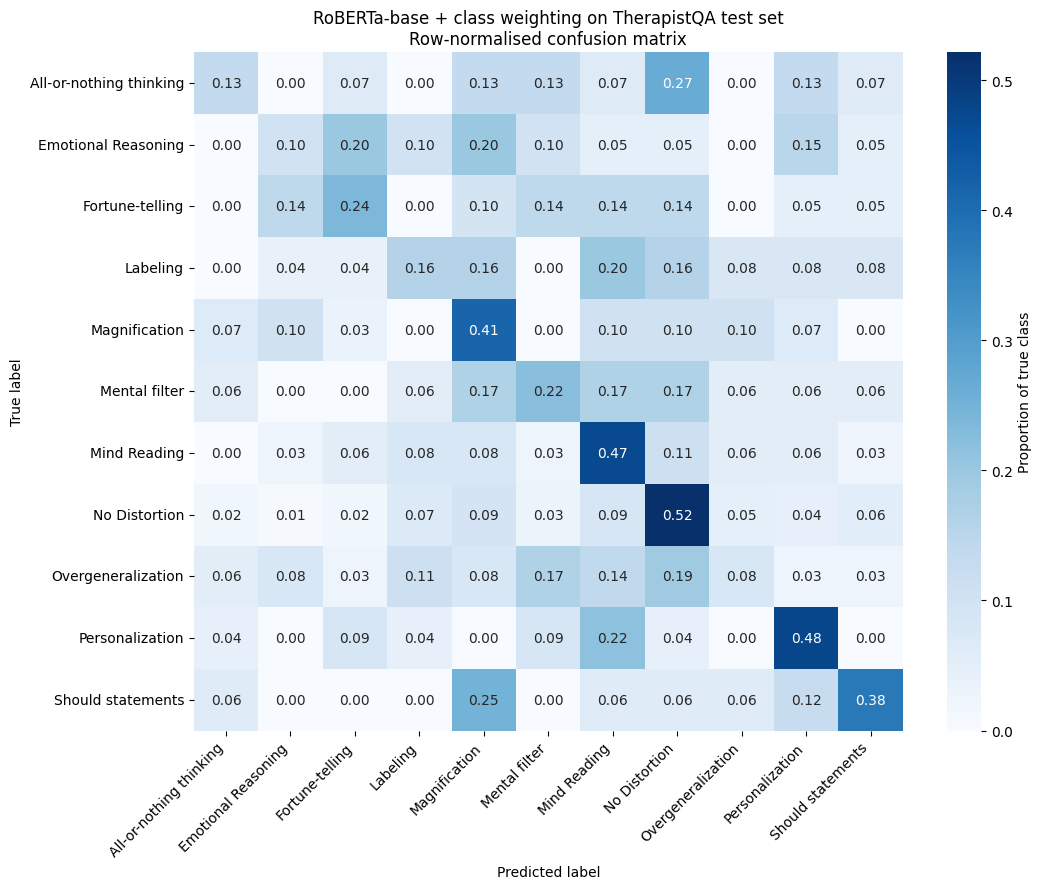

Saved confusion matrix to /content/drive/MyDrive/thesis_stage2/confusion_matrix_therapistqa_v3.png


In [7]:
test_predictions = trainer.predict(tokenized_datasets["test"])
y_pred = np.argmax(test_predictions.predictions, axis=-1)
y_true = test_predictions.label_ids

print("=== Test set metrics ===")
for k, v in test_predictions.metrics.items():
    print(f"  {k}: {v:.4f}" if isinstance(v, float) else f"  {k}: {v}")

print("\n=== Per-category report ===")
print(classification_report(
    y_true, y_pred,
    target_names=[id2label[i] for i in range(len(id2label))],
    digits=3,
))

# Predictions CSV with per-class probabilities
predictions_df = pd.DataFrame({
    "y_true":     y_true,
    "y_pred":     y_pred,
    "true_label": [id2label[i] for i in y_true],
    "pred_label": [id2label[i] for i in y_pred],
    "text":       df_test["patient_question"].values,
})

probs = torch.nn.functional.softmax(
    torch.tensor(test_predictions.predictions), dim=-1
).numpy()
for idx in range(len(id2label)):
    predictions_df[f"prob_{id2label[idx]}"] = probs[:, idx]

predictions_csv = f"{DATA_DIR}/roberta_therapistqa_test_predictions_v3.csv"
predictions_df.to_csv(predictions_csv, index=False)
print(f"\nSaved predictions to {predictions_csv}")

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)
labels = [id2label[i] for i in range(len(id2label))]
cm_normalized = cm.astype(float) / cm.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(
    cm_normalized,
    annot=True, fmt=".2f", cmap="Blues",
    xticklabels=labels, yticklabels=labels,
    cbar_kws={"label": "Proportion of true class"},
    ax=ax,
)
ax.set_xlabel("Predicted label")
ax.set_ylabel("True label")
ax.set_title("RoBERTa-base + class weighting on TherapistQA test set\nRow-normalised confusion matrix")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()

cm_path = f"{DATA_DIR}/confusion_matrix_therapistqa_v3.png"
plt.savefig(cm_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved confusion matrix to {cm_path}")

Loading weights:   0%|          | 0/201 [00:01<?, ?it/s]

Full-text model has 11 classes; No Distortion is index 7
Original test set: 379
Distorted-only:    239


Map:   0%|          | 0/239 [00:00<?, ? examples/s]


Logits shape: (239, 11)

=== Full-text classifier evaluated on distorted-only 10-class test set ===
  Records:     239
  Accuracy:    0.3096
  F1 weighted: 0.2992
  F1 macro:    0.2876

=== Per-category report (10-class distorted-only) ===
                         precision    recall  f1-score   support

All-or-nothing thinking      0.222     0.133     0.167        15
    Emotional Reasoning      0.154     0.100     0.121        20
        Fortune-telling      0.294     0.238     0.263        21
               Labeling      0.250     0.200     0.222        25
          Magnification      0.333     0.448     0.382        29
          Mental filter      0.200     0.222     0.211        18
           Mind Reading      0.354     0.472     0.405        36
     Overgeneralization      0.281     0.250     0.265        36
        Personalization      0.407     0.478     0.440        23
      Should statements      0.429     0.375     0.400        16

               accuracy                   

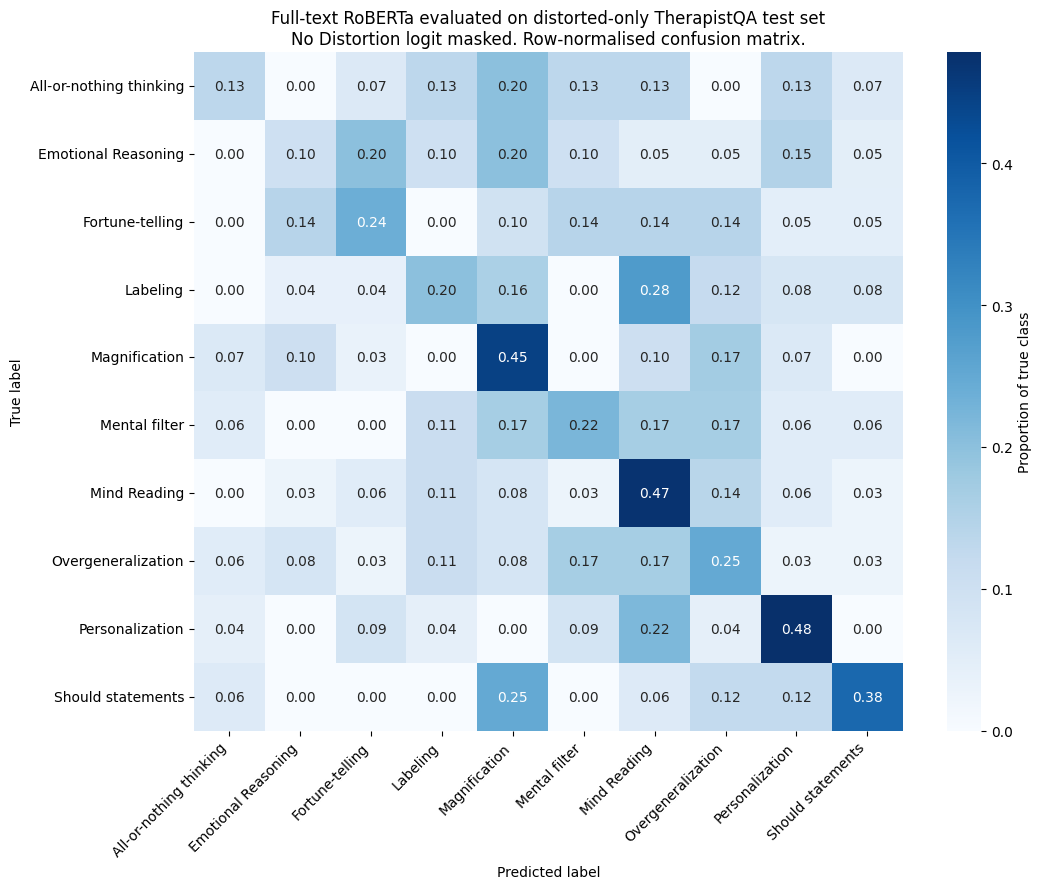

Saved confusion matrix to /content/drive/MyDrive/thesis_stage2/confusion_matrix_therapistqa_fulltext_on_distorted_only.png


In [3]:
# === Cross-evaluation: full-text classifier on distorted-only 10-class subset ===
import pandas as pd
import numpy as np
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    f1_score, accuracy_score, classification_report, confusion_matrix,
)
from transformers import (
    AutoTokenizer, AutoModelForSequenceClassification,
    Trainer, TrainingArguments, DataCollatorWithPadding,
)
from datasets import Dataset

DATA_DIR        = "/content/drive/MyDrive/thesis_stage2"
FULLTEXT_MODEL  = f"{DATA_DIR}/roberta_therapistqa_final_v3"

# 1) Load full-text model and tokenizer
tokenizer = AutoTokenizer.from_pretrained(FULLTEXT_MODEL)
model     = AutoModelForSequenceClassification.from_pretrained(FULLTEXT_MODEL)
model.eval()

id2label_full = model.config.id2label
label2id_full = model.config.label2id

# Sanity: confirm No Distortion is one of the labels
assert "No Distortion" in label2id_full, "Expected No Distortion in full-text label set"
no_distortion_idx = label2id_full["No Distortion"]
print(f"Full-text model has {len(id2label_full)} classes; No Distortion is index {no_distortion_idx}")

# 2) Load test set, filter to distorted only — same filter as 3A used
df_test_full = pd.read_csv(f"{DATA_DIR}/therapistqa_test.csv")
df_test_dist = df_test_full[df_test_full["is_distorted"] == True].reset_index(drop=True)
print(f"Original test set: {len(df_test_full)}")
print(f"Distorted-only:    {len(df_test_dist)}")

# 3) Tokenise the patient_question column with the full-text model's tokenizer
test_dataset = Dataset.from_pandas(
    df_test_dist[["patient_question", "dominant_distortion"]]
        .rename(columns={"patient_question": "text"})
        .assign(label=lambda d: d["dominant_distortion"].map(label2id_full))
        [["text", "label"]],
    preserve_index=False,
)

def tokenize_function(batch):
    return tokenizer(batch["text"], truncation=True, max_length=512)

tokenized_test = test_dataset.map(tokenize_function, batched=True, remove_columns=["text"])

# 4) Run inference using a Trainer in predict-only mode
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)
predict_args = TrainingArguments(
    output_dir="/tmp/predict_only",
    per_device_eval_batch_size=32,
    report_to="none",
)
predict_trainer = Trainer(
    model=model, args=predict_args,
    processing_class=tokenizer, data_collator=data_collator,
)
raw_predictions = predict_trainer.predict(tokenized_test)
logits = raw_predictions.predictions  # shape (239, 11)
y_true_full = raw_predictions.label_ids

print(f"\nLogits shape: {logits.shape}")

# 5) Mask the No Distortion logit so argmax is forced into the 10 distortion classes
masked_logits = logits.copy()
masked_logits[:, no_distortion_idx] = -np.inf
y_pred_full = np.argmax(masked_logits, axis=-1)

# Sanity check: nobody predicted No Distortion after masking
assert (y_pred_full != no_distortion_idx).all(), "Masking failed"

# 6) Build the 3A 10-class label space and remap predictions and labels into it
distortion_classes = sorted([c for c in label2id_full.keys() if c != "No Distortion"])
label2id_10 = {c: i for i, c in enumerate(distortion_classes)}
id2label_10 = {i: c for c, i in label2id_10.items()}

# Map the full-text-model indices to 10-class indices
full_to_10 = {label2id_full[c]: label2id_10[c] for c in distortion_classes}
y_true_10 = np.array([full_to_10[i] for i in y_true_full])
y_pred_10 = np.array([full_to_10[i] for i in y_pred_full])

# 7) Aggregate metrics on the 10-class distorted-only evaluation
accuracy    = accuracy_score(y_true_10, y_pred_10)
f1_weighted = f1_score(y_true_10, y_pred_10, average="weighted")
f1_macro    = f1_score(y_true_10, y_pred_10, average="macro")

print("\n=== Full-text classifier evaluated on distorted-only 10-class test set ===")
print(f"  Records:     {len(y_true_10)}")
print(f"  Accuracy:    {accuracy:.4f}")
print(f"  F1 weighted: {f1_weighted:.4f}")
print(f"  F1 macro:    {f1_macro:.4f}")

# 8) Per-category report in the 10-class label space
print("\n=== Per-category report (10-class distorted-only) ===")
print(classification_report(
    y_true_10, y_pred_10,
    target_names=[id2label_10[i] for i in range(len(id2label_10))],
    digits=3,
))

# 9) Save predictions for the writeup
out_df = pd.DataFrame({
    "y_true_10": y_true_10,
    "y_pred_10": y_pred_10,
    "true_label": [id2label_10[i] for i in y_true_10],
    "pred_label": [id2label_10[i] for i in y_pred_10],
    "patient_question": df_test_dist["patient_question"].values,
})
out_path = f"{DATA_DIR}/roberta_therapistqa_fulltext_on_distorted_only_predictions.csv"
out_df.to_csv(out_path, index=False)
print(f"\nSaved cross-evaluation predictions to {out_path}")

# 10) Confusion matrix for the cross-evaluation
cm = confusion_matrix(y_true_10, y_pred_10)
labels_10 = [id2label_10[i] for i in range(len(id2label_10))]
cm_normalized = cm.astype(float) / cm.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(
    cm_normalized,
    annot=True, fmt=".2f", cmap="Blues",
    xticklabels=labels_10, yticklabels=labels_10,
    cbar_kws={"label": "Proportion of true class"},
    ax=ax,
)
ax.set_xlabel("Predicted label")
ax.set_ylabel("True label")
ax.set_title(
    "Full-text RoBERTa evaluated on distorted-only TherapistQA test set\n"
    "No Distortion logit masked. Row-normalised confusion matrix."
)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()

cm_path = f"{DATA_DIR}/confusion_matrix_therapistqa_fulltext_on_distorted_only.png"
plt.savefig(cm_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved confusion matrix to {cm_path}")